# 07 - SVM trên Animal dataset

Mục tiêu: mã hóa các triệu chứng categorical bằng OneHotEncoder và chọn SVM bằng cross-validation để dự đoán `Dangerous`.

## 1. Load data và EDA ngắn

Shape ban đầu: (871, 7)
Missing values:
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64
Unique Dangerous: ['Yes' 'No' nan]
Phân bố target sau khi bỏ target thiếu:
Dangerous
Yes    849
No      20
Name: count, dtype: int64
AnimalName có nhiều hơn một nhãn: 3


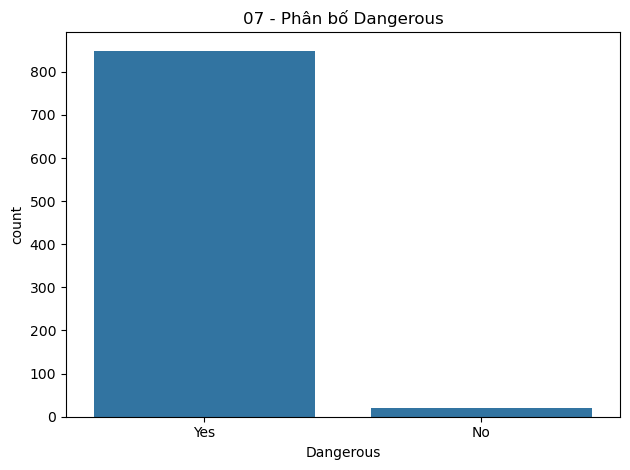

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'animal.csv'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
RANDOM_STATE = 24

df = pd.read_csv(DATA)
print('Shape ban đầu:', df.shape)
print('Missing values:')
print(df.isna().sum())
print('Unique Dangerous:', df['Dangerous'].unique())
df = df.dropna(subset=['Dangerous']).copy()
df['Dangerous'] = df['Dangerous'].astype(str).str.strip()
print('Phân bố target sau khi bỏ target thiếu:')
print(df['Dangerous'].value_counts())
mapping_counts = df.groupby('AnimalName')['Dangerous'].nunique()
print('AnimalName có nhiều hơn một nhãn:', int((mapping_counts > 1).sum()))
sns.countplot(data=df, x='Dangerous')
plt.title('07 - Phân bố Dangerous')
plt.tight_layout()
plt.savefig(FIGURES / '07_animal_target_distribution.png', dpi=150)
plt.show()

## 2. Tiền xử lý và tuning

`AnimalName` được bỏ vì mỗi tên động vật ánh xạ tới một nhãn duy nhất trong dữ liệu hợp lệ, có thể tạo leakage. Chỉ dùng năm cột symptoms làm feature.

In [2]:
X = df.drop(columns=['Dangerous', 'AnimalName'])
y = df['Dangerous']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
feature_columns = list(X.columns)
preprocessor = ColumnTransformer([
    ('categorical', Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore')), ('scale', StandardScaler(with_mean=False))]), feature_columns),
])
pipeline = Pipeline([('preprocessor', preprocessor), ('svc', SVC(probability=True, random_state=RANDOM_STATE))])
param_grid = {
    'svc__C': [0.1, 1, 10],
    'svc__kernel': ['linear', 'rbf'],
    'svc__gamma': ['scale', 0.1],
}
search = GridSearchCV(pipeline, param_grid, scoring='roc_auc', cv=4, n_jobs=-1, error_score=np.nan, return_train_score=True)
search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print('Best CV ROC AUC:', search.best_score_)

Best params: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Best CV ROC AUC: 0.9690415071353985


## 3. Đánh giá

accuracy     1.0
precision    1.0
recall       1.0
f1           1.0
roc_auc      1.0
dtype: float64
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



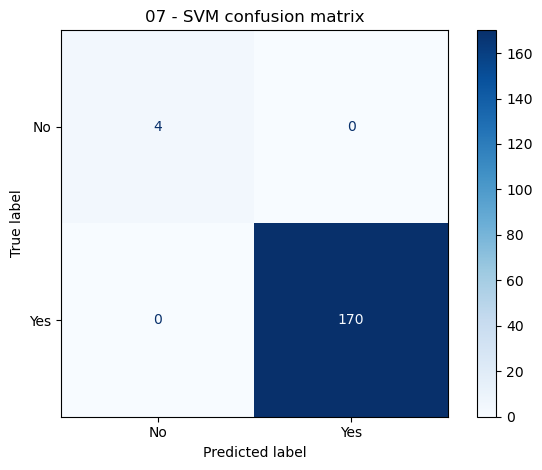

Đã cập nhật results_summary.csv


In [3]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
positive_label = 'Yes'
y_proba = best_model.predict_proba(X_test)[:, list(best_model.classes_).index(positive_label)]
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'recall': recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'f1': f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'roc_auc': roc_auc_score((y_test == positive_label).astype(int), y_proba),
}
print(pd.Series(metrics))
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=best_model.classes_), display_labels=best_model.classes_).plot(cmap='Blues', values_format='d')
plt.title('07 - SVM confusion matrix')
plt.tight_layout()
plt.savefig(FIGURES / '07_animal_svm_confusion_matrix.png', dpi=150)
plt.show()

summary_path = FIGURES / 'results_summary.csv'
summary = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame(columns=['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
summary = summary[summary['notebook'] != '07_animal_svm']
summary.loc[len(summary)] = ['07_animal_svm', 'animal', 'SVM', str(search.best_params_), metrics['accuracy'], metrics['precision'], metrics['recall'], metrics['f1'], metrics['roc_auc']]
summary.to_csv(summary_path, index=False)
print('Đã cập nhật results_summary.csv')

## 4. Nhận xét và bảng tóm tắt

Chọn model theo ROC AUC của cross-validation. `OneHotEncoder(handle_unknown='ignore')` và `StandardScaler` nằm trong Pipeline để tránh data leakage; test set chỉ dùng một lần cho đánh giá cuối.